---
# Executed by scripts/export_gw_examples.py; the docs build shows the stored outputs.
execute:
  skip: true
---
# 6. Kerr ringdown in real detector noise

This page was generated from [`notebooks/gw/06_ringdown_real_noise.py`](https://github.com/Potatoasad/astroinfer/blob/main/notebooks/gw/06_ringdown_real_noise.py), a marimo notebook. Sliders and other controls are shown at their default values. To change them, run the notebook with `uv run marimo edit notebooks/gw/06_ringdown_real_noise.py`.

Notebook 5 fitted a Kerr ringdown in Gaussian noise of a known PSD. Real detector noise is
neither: its PSD has to be estimated from the data, and it has lines, glitches and slow drifts
that a Gaussian model does not describe. This notebook repeats the fit of notebook 5 in real
noise from all three detectors of the second observing run, Hanford (H1), Livingston (L1) and
Virgo (V1).

The data are public strain from GWOSC, around GW170814, the first binary black hole seen by
all three detectors. We take 256 s centred 200 s after that event, so the event itself is not
in the data, estimate each detector's PSD from them, and add the ringdown of notebook 5 to
the analysis segment. The fetching, conditioning and PSD estimation are done by ringdown's
`Fit` object; astroinfer takes over once the data are conditioned.

This notebook needs gwpy and ringdown, which are in the `ringdown` dependency group:

```bash
uv run --group ringdown marimo edit notebooks/gw/06_ringdown_real_noise.py
```

The first run downloads one 4096 s file per detector from GWOSC, about 3 minutes in all; gwpy
caches them for later runs.

In [1]:
import sys
from pathlib import Path

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts" / "marimo_docs_shim.py").is_file())
sys.path[:0] = [str(ROOT / "notebooks/gw"), str(ROOT / "scripts")]

import marimo_docs_shim
marimo_docs_shim.set_notebook_dir(ROOT / "notebooks/gw")
sys.modules["marimo"] = marimo_docs_shim

# marimo shows a figure only when a cell returns it. Stop Jupyter from also showing every
# figure a cell creates, and close them once the cell has run.
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import flush_figures
get_ipython().run_line_magic("matplotlib", "inline")
try:
    get_ipython().events.unregister("post_execute", flush_figures)
except ValueError:
    pass
get_ipython().events.register("post_execute", lambda: plt.close("all"))

# Show astroinfer objects with their HTML display (as Jupyter does), not the short markdown one.
get_ipython().display_formatter.formatters["text/markdown"].enabled = False
# Open every object display, so readers see the contents without having to click.
import astroinfer.display
astroinfer.display.set_options(expanded=True)


In [2]:
import jax

jax.config.update("jax_enable_x64", True)

from dataclasses import dataclass

import astroinfer as ai
import gwpy.timeseries  # noqa: F401  (ringdown fetches open data through gwpy)
import jax.numpy as jnp
import matplotlib as mpl
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import ringdown as rd
import scipy.stats
from astroinfer import MeasurementProcess, batched_method, parameter, parameter_dataclass
from astroinfer.display import html_value
from jax.scipy.linalg import solve_triangular
from numpyro.distributions import constraints

# Importing gwpy changes matplotlib's defaults and replaces its default Axes class; restore
# both, so that the plots look like those of notebooks 4 and 5.
mpl.rcdefaults()
mpl.projections.register_projection(mpl.axes.Axes)

# The colors of tutorials/_style.py, and one per detector.
POSTERIOR, PRIOR, DATA, TRUTH = "#418FC5", "#eb6834", "#1baf7a", "#17243D"
IFO_COLORS = {"H1": "#e34948", "L1": "#418FC5", "V1": "#6250d6"}

T_MSUN = 4.925491025543576e-06  # G M_sun / c^3, in seconds
STRAIN_UNIT = 1e-21             # strain is measured in units of 1e-21 throughout
MODES = ("220", "221")          # (l, m, n) of the modes in the fit

IFOS = ["H1", "L1", "V1"]
T_GW170814 = 1186741861.5       # GPS time of GW170814
T_INJECTION = T_GW170814 + 200  # geocenter start time of the injected ringdown
HALF_LENGTH = 128

## Fetching and conditioning the data

ringdown's preprocessing takes four calls:

1. `load_data` fetches the strain of each detector from GWOSC through gwpy, here at 4096 Hz.
2. `set_target` fixes the start of the analysis at geocenter, the sky position and the
   polarization angle. From them it computes, with LAL, the time at which the signal reaches
   each detector and the antenna patterns $(F_+, F_\times)$ of each detector. We use the sky
   position and polarization angle of ringdown's GW150914 example, $\alpha = 1.95$,
   $\delta = -1.27$, $\psi = 0.82$, and the same 0.2 s segment.
3. `condition_data` high-passes each series above 20 Hz with a fourth-order Butterworth
   filter applied forwards and backwards, downsamples it by 2 to 2048 Hz by removing the Fourier components above the new
   Nyquist frequency, and trims 25% from each end to remove the filters' edge effects. It
   keeps the sample nearest each detector's start time.
4. `compute_acfs` estimates the PSD of the whole conditioned series by Welch's method and
   turns it into an autocovariance, as in notebook 5. The Welch segments are 4 s long, the
   next power of two above 16 analysis segments.

In [3]:
fit = rd.Fit()
fit.load_data(ifos=IFOS, channel="GWOSC", start=T_INJECTION - HALF_LENGTH,
              end=T_INJECTION + HALF_LENGTH, sample_rate=4096, cache=True)
fit.set_target(T_INJECTION, ra=1.95, dec=-1.27, psi=0.82, duration=0.2)
fit.condition_data(ds=2, f_min=20)
fit.compute_acfs(f_min=20)
{ifo: f"{len(d)} samples, {d.duration:.0f} s" for ifo, d in fit.data.items()}

{'H1': '262144 samples, 128 s',
 'L1': '262144 samples, 128 s',
 'V1': '262144 samples, 128 s'}

After conditioning, each detector has 128 s of data at 2048 Hz. The analysis segment starts
at a different time in each detector, because the signal arrives at different times. ringdown
gives the delays after the geocenter time, in milliseconds, and the antenna patterns:

In [4]:
{ifo: {"delay [ms]": round(1e3 * (float(fit.start_times[ifo]) - T_INJECTION), 2),
       "F+": round(fit.antenna_patterns[ifo][0], 3),
       "Fx": round(fit.antenna_patterns[ifo][1], 3)}
 for ifo in fit.ifos}

{'H1': {'delay [ms]': 16.11, 'F+': 0.208, 'Fx': -0.758},
 'L1': {'delay [ms]': 9.42, 'F+': -0.303, 'Fx': 0.516},
 'V1': {'delay [ms]': 9.66, 'F+': -0.091, 'Fx': 0.573}}

## The estimated noise

`fit.psds` converts each autocovariance back into the PSD it came from. The two LIGO
detectors have similar sensitivity at the ringdown frequency, around 245 Hz, and Virgo is
several times less sensitive:

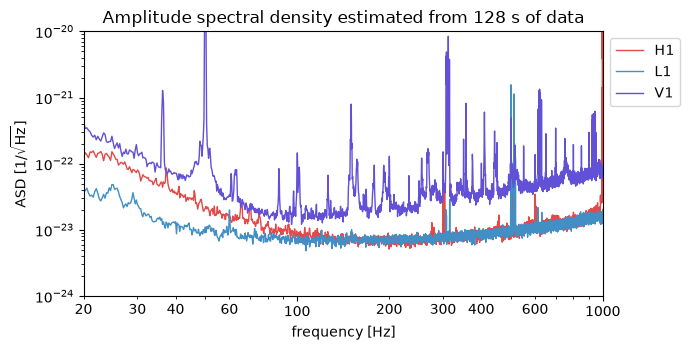

In [5]:
_fig, _ax = plt.subplots(figsize=(7.0, 3.6))
for _ifo, _psd in fit.psds.items():
    _f = np.asarray(_psd.index)
    _keep = (_f >= 20) & (_f <= 1000)
    _ax.loglog(_f[_keep], np.sqrt(np.asarray(_psd)[_keep]), color=IFO_COLORS[_ifo],
               linewidth=1, label=_ifo)
_ax.set(xlim=(20, 1000), ylim=(1e-24, 1e-20), xlabel="frequency [Hz]",
        ylabel=r"ASD [1/$\sqrt{\mathrm{Hz}}$]",
        title="Amplitude spectral density estimated from 128 s of data")
_ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
_fig.tight_layout()
_fig

The likelihood assumes that each analysis segment is Gaussian with the covariance built from
this estimate. We can test that on the noise itself. Whitened by the Cholesky factor $L$ of
the covariance, a segment of $n = 410$ samples should be $n$ independent standard normals, so
$\chi^2/n = |L^{-1}x|^2/n$ should follow a $\chi^2_n/n$ distribution, with mean 1 and
standard deviation $\sqrt{2/n} \approx 0.07$. We cut the 128 s of each detector into 639
consecutive segments:

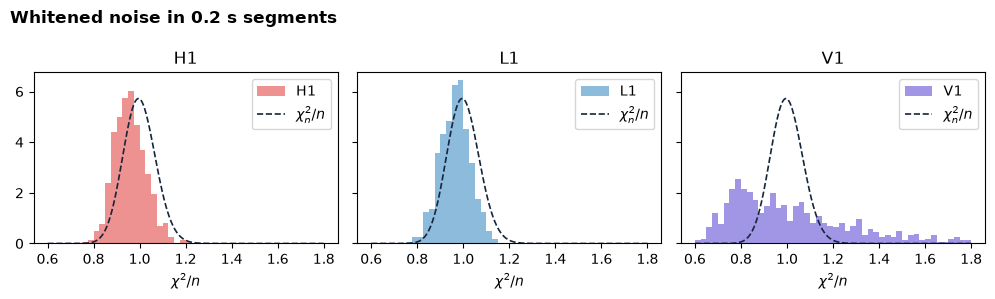

In [6]:
def whitened_chi2(ifo):
    """chi^2 / n of the consecutive analysis-length segments of one detector."""
    x, n = np.asarray(fit.data[ifo]), fit.n_analyze
    segments = np.stack([x[j:j + n] for j in range(0, len(x) - n, n)])
    w = np.linalg.solve(fit.cholesky_factors[ifo], segments.T)
    return np.mean(w**2, axis=0)

chi2 = {ifo: whitened_chi2(ifo) for ifo in fit.ifos}

_n = fit.n_analyze
_grid = np.linspace(0.6, 1.8, 300)
_fig, _axes = plt.subplots(1, 3, figsize=(10.0, 3.0), sharey=True)
for _ax, (_ifo, _c) in zip(_axes, chi2.items()):
    _ax.hist(_c, bins=np.linspace(0.6, 1.8, 49), density=True, color=IFO_COLORS[_ifo],
             alpha=0.6, label=_ifo)
    _ax.plot(_grid, _n * scipy.stats.chi2(_n).pdf(_n * _grid), color=TRUTH, linestyle="--",
             linewidth=1.2, label=r"$\chi^2_n/n$")
    _ax.set(xlabel=r"$\chi^2/n$", title=_ifo)
    _ax.legend(loc="upper right")
_fig.suptitle("Whitened noise in 0.2 s segments", x=0.01, ha="left", fontweight="bold")
_fig.tight_layout()
_fig

In [7]:
{ifo: {"mean": round(float(np.mean(c)), 3),
       "5%": round(float(np.percentile(c, 5)), 3),
       "95%": round(float(np.percentile(c, 95)), 3)}
 for ifo, c in chi2.items()}

{'H1': {'mean': 0.958, '5%': 0.859, '95%': 1.07},
 'L1': {'mean': 0.965, '5%': 0.853, '95%': 1.074},
 'V1': {'mean': 1.031, '5%': 0.695, '95%': 1.593}}

For Gaussian segments, 90% of the values of $\chi^2/n$ would fall between 0.89 and 1.12.
The two LIGO detectors are close to that: their 5% and 95% points are 0.86 and 1.07 for
Hanford and 0.85 and 1.07 for Livingston. Their means, 0.958 and 0.965, are about 4% below 1,
so the estimated covariance is on average a few percent too large, which makes the
likelihood a little broader than it should be. Virgo's values spread far more widely, from
0.70 to 1.59, on both sides of 1, so its noise level changes over the 128 s more than one PSD
can describe. Virgo contributes little to the signal-to-noise ratio of the injection below,
so we keep it; with a louder signal in Virgo, a shorter stretch for its PSD estimate, or
leaving it out, would be the safer choice.

## The parameter types

The source types are those of notebook 5: the remnant, the quadratures of each mode, and the
nested `KerrRingdown`. The Kerr spectrum is the same fit of Berti, Cardoso and Will (2006).

In [8]:
def kerr_qnms(M, chi):
    """Frequencies [Hz] and damping rates [1/s] of the 220 and 221 modes of a Kerr black hole.

    M is the detector-frame mass in solar masses and chi the dimensionless spin.
    """
    # Berti, Cardoso & Will (2006), Table VIII: (f1, f2, f3) and (q1, q2, q3) for n = 0, 1.
    f_fit = jnp.array([[1.5251, -1.1568, 0.1292], [1.3673, -1.0260, 0.1628]])
    q_fit = jnp.array([[0.7000, 1.4187, -0.4990], [0.1000, 0.5436, -0.4731]])
    x = 1.0 - chi
    M_omega = f_fit[:, 0] + f_fit[:, 1] * x ** f_fit[:, 2]
    Q = q_fit[:, 0] + q_fit[:, 1] * x ** q_fit[:, 2]
    f = M_omega / (2 * jnp.pi * M * T_MSUN)
    return f, jnp.pi * f / Q

In [9]:
@parameter_dataclass(name="Remnant", latex=r"\theta_f")
class Remnant:
    M: float = parameter(name="Detector-frame mass [M_sun]", latex="M",
                         support=constraints.positive)
    chi: float = parameter(name="Dimensionless spin", latex=r"\chi",
                           support=constraints.interval(0.0, 0.99))

    @batched_method
    def qnms(self):
        """``(f, gamma)``, each with one entry per mode."""
        return kerr_qnms(self.M, self.chi)

In [10]:
@parameter_dataclass(name="Quadratures", latex="a")
class Quadratures:
    ax: float = parameter(name="Cosine quadrature [1e-21]", latex="a_x", index=("mode",),
                          index_latex=("n",))
    ay: float = parameter(name="Sine quadrature [1e-21]", latex="a_y", index=("mode",),
                          index_latex=("n",))

In [11]:
@parameter_dataclass(name="Kerr ringdown", latex=r"\theta")
class KerrRingdown:
    remnant: Remnant
    modes: Quadratures

In [12]:
@parameter_dataclass(name="Network strain", latex="d")
class NetworkStrain:
    h: float = parameter(name="Strain [1e-21]", latex="d", index=("ifo", "time"),
                         index_latex=("I", "k"))

## The detector configuration

`DetectorConfig` is that of notebook 5 with one change. The sample times now have the axes
`("ifo", "time")`: they are measured from each detector's own start time, and ringdown keeps
the sample nearest that time, so the first sample of a segment can be up to half a sample,
0.24 ms, off its start time, by a different amount in each detector. The methods that do the
algebra over the detector axis do not change. `from_ringdown` reads everything the
configuration holds from a conditioned `Fit`, and `strain_from_ringdown` reads the analysis
segments as a `NetworkStrain`, both in units of $10^{-21}$.

In [13]:
@parameter_dataclass(name="Detector network", latex="D")
class DetectorConfig:
    t: float = parameter(name="Time since the start of the segment [s]", latex="t",
                         index=("ifo", "time"), index_latex=("I", "k"))
    fp: float = parameter(name="Plus antenna pattern", latex="F_+", index=("ifo",),
                          index_latex=("I",))
    fc: float = parameter(name="Cross antenna pattern", latex=r"F_\times", index=("ifo",),
                          index_latex=("I",))
    cholesky: float = parameter(name="Cholesky factor of the noise covariance", latex="L",
                                index=("ifo", "time", "time"), index_latex=("I", "k", "k'"))

    @classmethod
    def from_ringdown(cls, fit, scale=STRAIN_UNIT):
        """The analysis times, antenna patterns and noise of a conditioned ringdown ``Fit``."""
        ifos = fit.ifos
        return cls(
            t=jnp.stack([fit.analysis_times[i] - float(fit.start_times[i]) for i in ifos]),
            fp=jnp.array([fit.antenna_patterns[i][0] for i in ifos]),
            fc=jnp.array([fit.antenna_patterns[i][1] for i in ifos]),
            cholesky=jnp.stack([fit.cholesky_factors[i] for i in ifos]) / scale,
        )

    @property
    def shape(self):
        """``(number of detectors, number of samples)``, the core shape of the strain."""
        return self.fp.shape[-1], self.t.shape[-1]

    def project(self, hp, hc):
        """The strain in each detector from the polarizations, each of shape ``(ifo, time)``."""
        return self.fp[:, None] * hp + self.fc[:, None] * hc

    def whiten(self, x):
        """``L^{-1} x`` in each detector, for ``x`` of shape ``(ifo, time)``."""
        return jax.vmap(lambda L, y: solve_triangular(L, y, lower=True))(self.cholesky, x)

    def color(self, z):
        """``L z`` in each detector: noise with this covariance when ``z`` is standard normal."""
        return jnp.einsum("ikl,il->ik", self.cholesky, z)

    def log_likelihood(self, residual):
        """Gaussian log density of a residual of shape ``(ifo, time)``."""
        w = self.whiten(residual)
        log_det = jnp.sum(jnp.log(jnp.diagonal(self.cholesky, axis1=-2, axis2=-1)))
        return -0.5 * jnp.sum(w**2) - log_det - 0.5 * w.size * jnp.log(2 * jnp.pi)

    def snr(self, h):
        """Optimal signal-to-noise ratio of the strain ``h`` in each detector."""
        return jnp.sqrt(jnp.sum(self.whiten(h) ** 2, axis=-1))

In [14]:
def strain_from_ringdown(fit, scale=STRAIN_UNIT):
    """The analysis segments of a conditioned ringdown ``Fit`` as a ``NetworkStrain``."""
    return NetworkStrain(h=jnp.stack([np.asarray(fit.analysis_data[i]) for i in fit.ifos]) / scale)

In [15]:
detectors = DetectorConfig.from_ringdown(fit)
detectors

DetectorConfig(batch_shape=(), t=(3, 410), fp=(3,), fc=(3,), cholesky=(3, 410, 410))

## The measurement process

`Network` is that of notebook 5: a face-off source, $\cos\iota = -1$, with the polarizations
computed on the time grid of each detector and everything else handed to the configuration.

In [16]:
@dataclass(eq=False)
class Network(MeasurementProcess):
    detectors: DetectorConfig
    ifos: tuple = ("H1", "L1", "V1")
    cosi: float = -1.0

    display_name = "Kerr ringdown in a detector network"
    parameter_type = KerrRingdown
    data_type = NetworkStrain

    def __post_init__(self):
        # Reading the batch shape checks that the named axes agree across fields.
        if self.detectors.batch_shape:
            raise ValueError("detectors must describe one network, without batch axes")
        if len(self.ifos) != self.detectors.shape[0]:
            raise ValueError(
                f"{len(self.ifos)} detector names for {self.detectors.shape[0]} detectors"
            )

    def polarizations(self, theta):
        """``(h_+, h_x)``, each of shape ``(ifo, time)``."""
        t = self.detectors.t
        f, gamma = kerr_qnms(theta.remnant.M, theta.remnant.chi)
        phase = 2 * jnp.pi * f[:, None, None] * t
        decay = jnp.exp(-gamma[:, None, None] * t)
        ax, ay = theta.modes.ax[:, None, None], theta.modes.ay[:, None, None]
        hp = jnp.sum(decay * (ax * jnp.cos(phase) + ay * jnp.sin(phase)), axis=0)
        hc = jnp.sum(decay * (ax * jnp.sin(phase) - ay * jnp.cos(phase)), axis=0)
        return 0.5 * (1 + self.cosi**2) * hp, self.cosi * hc

    def signal(self, theta):
        return self.detectors.project(*self.polarizations(theta))

    def sample_single(self, theta, key):
        noise = self.detectors.color(jax.random.normal(key, self.detectors.shape))
        return NetworkStrain(h=self.signal(theta) + noise)

    def logpdf_single(self, d, theta):
        return self.detectors.log_likelihood(d.h - self.signal(theta))

    def derived_parameters_single(self, theta):
        return {"snr": self.detectors.snr(self.signal(theta))}

    def _display_config(self):
        return {
            "detectors": html_value(self.detectors._repr_html_()),
            "names": ", ".join(self.ifos),
            "cos iota": self.cosi,
        }

## The injection

The remnant is that of notebook 5, $M = 70\,M_\odot$ and $\chi = 0.7$, with phases 0.5 and
2.0. The detectors are less sensitive than the design curve of notebook 5, so both modes have
an amplitude of $3\times10^{-21}$ instead of $10^{-21}$, which gives about the same network
signal-to-noise ratio. The optimal signal-to-noise ratio in each detector, and in the network:

In [17]:
network = Network(detectors, ifos=tuple(fit.ifos))
_amplitude, _phase = jnp.array([3.0, 3.0]), jnp.array([0.5, 2.0])
truth = KerrRingdown(
    remnant=Remnant(M=70.0, chi=0.7),
    modes=Quadratures(ax=_amplitude * jnp.cos(_phase), ay=_amplitude * jnp.sin(_phase)),
)
_snr = network.derived_parameters(truth)["snr"]
dict(zip(network.ifos, np.round(np.asarray(_snr), 1).tolist())), round(float(jnp.linalg.norm(_snr)), 1)

({'H1': 15.7, 'L1': 10.8, 'V1': 2.0}, 19.1)

Virgo contributes little: its signal-to-noise ratio is about 2. The data are the conditioned
real noise of each analysis segment plus the signal. We add the signal after conditioning, so
that the injected strain is exactly the model's, and the noise is the detectors' own:

In [18]:
noise = strain_from_ringdown(fit)
data = NetworkStrain(h=noise.h + network.signal(truth))
mo.hstack([truth, network, data], justify="start", gap=2, align="start")

KerrRingdown(batch_shape=(), remnant=Remnant(batch_shape=(), M=(), chi=()), modes=Quadratures(batch_shape=(), ax=(2,), ay=(2,)))

detectors,"Detector network:\({D}\)Time since the start of the segment [s]:\({t}_{I,k} =\)[[-4.7684e-07, 0.0005, 0.001, ...], ...]Array([[-4.76837158e-07, 4.87804413e-04, 9.76085663e-04, ..., 1.98729992e-01, 1.99218273e-01, 1.99706554e-01], [ 1.04427338e-04, 5.92708588e-04, 1.08098984e-03, ..., 1.98834896e-01, 1.99323177e-01, 1.99811459e-01], [ 1.00851059e-04, 5.89132309e-04, 1.07741356e-03, ..., 1.98831320e-01, 1.99319601e-01, 1.99807882e-01]], dtype=float64)shape=(3, 410)Plus antenna pattern:\({F_+}_{I} =\)[0.2085, -0.3034, -0.0908]Array([ 0.20846065, -0.30342571, -0.09075972], dtype=float64)shape=(3,)Cross antenna pattern:\({F_\times}_{I} =\)[-0.7578, 0.5161, 0.5732]Array([-0.75784376, 0.51610975, 0.57318996], dtype=float64)shape=(3,)Cholesky factor of the noise covariance:\({L}_{I,k,k'} =\)[[[25.5893, 0., 0., ...], ...], ...]Array(shape=(3, 410, 410), dtype=float64)shape=(3, 410, 410)Dimensions:\((\mathrm{ifo},\mathrm{time})=(I,k)\)shape=(3, 410)"
names,"H1, L1, V1"
cos iota,-1.0


NetworkStrain(batch_shape=(), h=(3, 410))

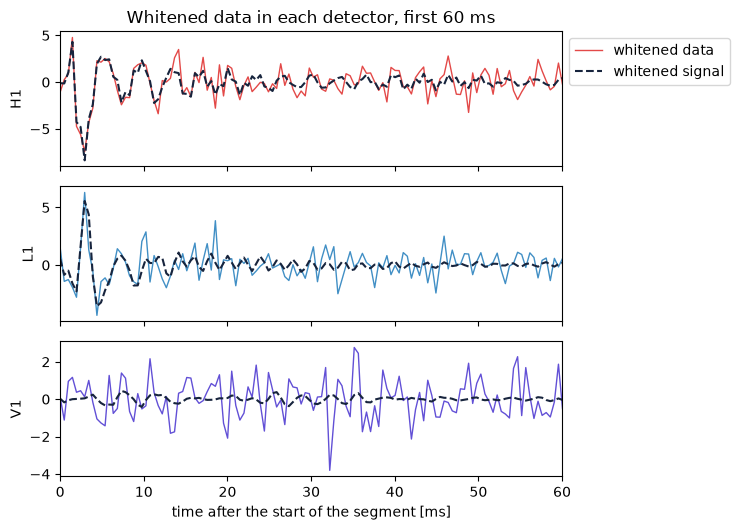

In [19]:
_t = 1e3 * np.asarray(network.detectors.t[0])
_wd = np.asarray(network.detectors.whiten(data.h))
_wh = np.asarray(network.detectors.whiten(network.signal(truth)))
_fig, _axes = plt.subplots(len(network.ifos), 1, figsize=(7.5, 5.4), sharex=True)
for _i, (_ax, _ifo) in enumerate(zip(_axes, network.ifos)):
    _ax.plot(_t, _wd[_i], color=IFO_COLORS[_ifo], linewidth=1, label="whitened data")
    _ax.plot(_t, _wh[_i], color=TRUTH, linestyle="--", linewidth=1.5, label="whitened signal")
    _ax.set(ylabel=_ifo, xlim=(0, 60))
_axes[0].set_title("Whitened data in each detector, first 60 ms")
_axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
_axes[-1].set(xlabel="time after the start of the segment [ms]")
_fig.tight_layout()
_fig

## The prior and the model

The prior and the model are those of notebook 5, including the bound of 50 on the amplitude
scale, which is ringdown's `a_scale_max` $= 5\times10^{-20}$ in our units.

In [20]:
def per_mode(distribution):
    """Independent copies of a scalar distribution, one per mode."""
    return distribution.expand([len(MODES)]).to_event(1)

prior = KerrRingdown.distribution(
    remnant=Remnant.distribution(M=dist.Uniform(40.0, 140.0), chi=dist.Uniform(0.0, 0.99)),
    modes=Quadratures.distribution(
        ax=lambda a_scale: dist.Normal(0.0, a_scale).to_event(1),
        ay=lambda a_scale: dist.Normal(0.0, a_scale).to_event(1),
    ),
).given({"a_scale": float})

In [21]:
def model(data):
    a_scale = ai.sample("a_scale", per_mode(dist.Uniform(0.0, 50.0)))
    theta = ai.sample("theta", prior, a_scale=a_scale)
    ai.sample("d", network, theta, obs=data)
    f, gamma = theta.remnant.qnms()
    numpyro.deterministic("f", f)
    numpyro.deterministic("tau", 1e3 / gamma)

ai.model_graph(model, data, expand=True)

Graph('Graph of model', nodes=['a_scale', 'theta.remnant.M', 'theta.remnant.chi', 'theta.modes.ax', 'theta.modes.ay', 'd', 'f', 'tau'], edges=[('a_scale', 'theta.modes.ax'), ('a_scale', 'theta.modes.ay'), ('theta.remnant.M', 'd'), ('theta.remnant.chi', 'd'), ('theta.modes.ax', 'd'), ('theta.modes.ay', 'd'), ('theta.remnant.M', 'f'), ('theta.remnant.chi', 'f'), ('theta.remnant.M', 'tau'), ('theta.remnant.chi', 'tau')])

In [22]:
posterior = ai.infer(model, data, seed=0, num_warmup=1000, num_samples=4000, summary=False)
posterior.summary(["theta.remnant.M", "theta.remnant.chi", "f", "tau"], expand=True)

,mean,sd,5.0%,95.0%,ess,r_hat
theta.remnant.M,64.672327,7.387759,51.784488,76.095190,1009.985445,0.999755
theta.remnant.chi,0.533668,0.183640,0.231695,0.814581,1005.636993,0.999764
f[0],243.069292,7.635047,229.493927,254.646054,1701.702558,1.001387
f[1],235.041762,8.196917,220.784871,247.459167,1690.837775,1.001203
tau[0],3.805919,0.606991,2.887547,4.742627,1051.558168,0.999971
tau[1],1.250443,0.204641,0.944486,1.566885,1054.208823,0.999987


The posterior mean of the mass is $64.7\,M_\odot$ with a standard deviation of 7.4, and that
of the spin is 0.53 with a standard deviation of 0.18. The 90% intervals, 51.8 to 76.1 and
0.23 to 0.81, contain the true values, 70 and 0.7. The fundamental mode has
$f = 243.1\pm7.6$ Hz and $\tau = 3.8\pm0.6$ ms, against true values of 246.9 Hz and 4.24 ms,
and the overtone has $\tau = 1.25\pm0.20$ ms against 1.40 ms. The run has no divergent
transitions.

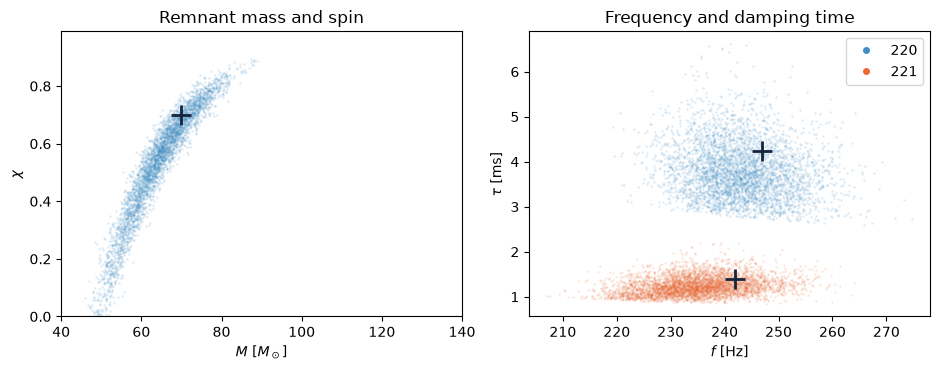

In [23]:
_theta = posterior.theta.theta
_M, _chi = np.asarray(_theta.remnant.M).ravel(), np.asarray(_theta.remnant.chi).ravel()
_f, _tau = np.asarray(posterior.extras["f"]), np.asarray(posterior.extras["tau"])
_f_true, _gamma_true = truth.remnant.qnms()

_fig, _axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
_axes[0].plot(_M, _chi, ".", color=POSTERIOR, alpha=0.1, markersize=2)
_axes[0].plot(float(truth.remnant.M), float(truth.remnant.chi), "+", color=TRUTH,
              markersize=14, mew=2)
_axes[0].set(xlim=(40, 140), ylim=(0, 0.99), xlabel=r"$M\ [M_\odot]$", ylabel=r"$\chi$",
             title="Remnant mass and spin")
for _i, (_mode, _color) in enumerate(zip(MODES, [POSTERIOR, PRIOR])):
    _axes[1].plot(_f[..., _i].ravel(), _tau[..., _i].ravel(), ".", color=_color, alpha=0.1,
                  markersize=2)
    _axes[1].plot([], [], ".", color=_color, markersize=8, label=_mode)
    _axes[1].plot(float(_f_true[_i]), 1e3 / float(_gamma_true[_i]), "+", color=TRUTH,
                  markersize=14, mew=2)
_axes[1].set(xlabel="$f$ [Hz]", ylabel=r"$\tau$ [ms]", title="Frequency and damping time")
_axes[1].legend(loc="upper right")
_fig.tight_layout()
_fig

The same pipeline fits a real event once the injection is left out: set the target to the
event's ringdown start time and sky position, and take the data as `strain_from_ringdown(fit)`
alone.